Hệ số chặn: 72.145397076255
Hệ số góc: 25.193599367838793
MSE: 1737.549474101784
R2 Score: 0.998736838023674

Nhà có diện tích 125 m2
Giá dự đoán: 3221.35 triệu VND


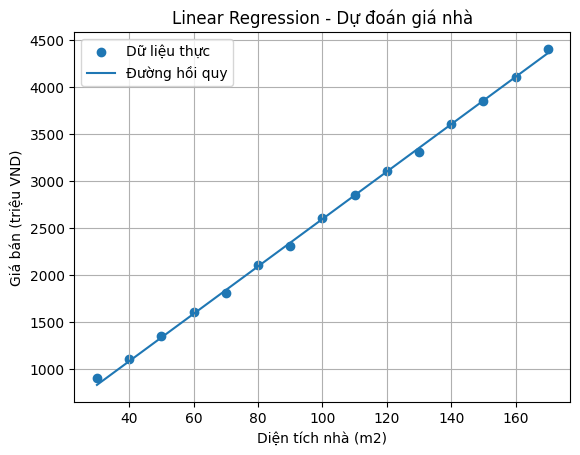

In [1]:
# BÀI 1.1: LINEAR REGRESSION - Dự đoán giá nhà theo diện tích
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# X: Diện tích nhà (m2)
# y: Giá bán (triệu VND)
X = np.array([
    [30], [40], [50], [60], [70],
    [80], [90], [100], [110], [120],
    [130], [140], [150], [160], [170]
])

y = np.array([
    900, 1100, 1350, 1600, 1800,
    2100, 2300, 2600, 2850, 3100,
    3300, 3600, 3850, 4100, 4400
])

X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Hệ số chặn:", model.intercept_)
print("Hệ số góc:", model.coef_[0])
print("MSE:", mse)
print("R2 Score:", r2)

dien_tich = 125
gia_du_doan = model.predict([[dien_tich]])

print(f"\nNhà có diện tích {dien_tich} m2")
print(f"Giá dự đoán: {gia_du_doan[0]:.2f} triệu VND")

plt.scatter(X, y, label="Dữ liệu thực")
plt.plot(X, model.predict(X), label="Đường hồi quy")

plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.title("Linear Regression - Dự đoán giá nhà")
plt.legend()
plt.grid()
plt.show()

Hệ số chặn: 385.49610555091704
Hệ số góc: 24.05564074108365
MSE: 104591.92219472045
R2 Score: 0.9369067973275902


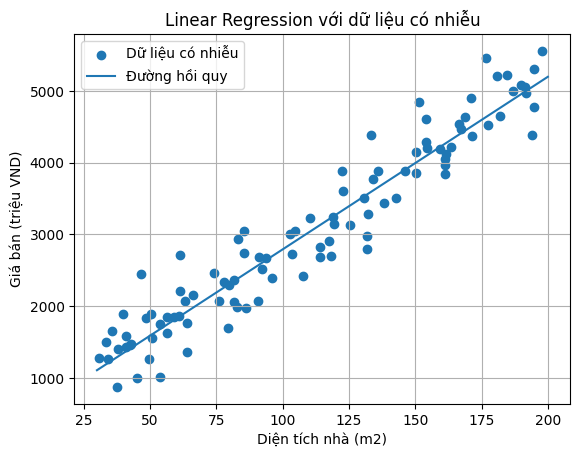

In [2]:
# BÀI 1.2: Thêm dữ liệu và độ nhiễu
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Tạo 100 căn nhà có diện tích từ 30 đến 200 m2
X = np.random.uniform(30, 200, 100).reshape(-1, 1)

# Công thức giá giả định
# Giá = 300 + 25 * diện tích + nhiễu
noise = np.random.normal(0, 400, 100)

y = 300 + 25 * X[:, 0] + noise

X_train, X_test, y_train, y_test = train_test_split(X, y,
      test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Hệ số chặn:", model.intercept_)
print("Hệ số góc:", model.coef_[0])
print("MSE:", mse)
print("R2 Score:", r2)

plt.scatter(X, y, label="Dữ liệu có nhiễu")
X_line = np.linspace(30, 200, 100).reshape(-1, 1)
y_line = model.predict(X_line)

plt.plot(X_line, y_line, label="Đường hồi quy")

plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.title("Linear Regression với dữ liệu có nhiễu")
plt.legend()
plt.grid()
plt.show()

In [3]:
# BÀI 1.3: Thêm nhiều biến
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

n = 100
dien_tich = np.random.uniform(30, 200, n)
so_phong = np.random.randint(1, 6, n)
tuoi_nha = np.random.randint(0, 30, n)

X = np.column_stack((dien_tich, so_phong, tuoi_nha))

noise = np.random.normal(0, 200, n)

y = (300 + 25 * dien_tich + 150 * so_phong - 20 * tuoi_nha + noise)

X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Hệ số chặn:", model.intercept_)
print("Hệ số góc:", model.coef_)
print("MSE:", mse)
print("R2 Score:", r2)

print("\nHệ số Diện tích:", model.coef_[0])
print("Hệ số Số phòng:", model.coef_[1])
print("Hệ số Tuổi nhà:", model.coef_[2])

# 120m2, 3 phòng ngủ, nhà 5 năm tuổi
nha_moi = [[120, 3, 5]]

gia = model.predict(nha_moi)

print("\nDự đoán căn nhà:")
print("Diện tích: 120 m2")
print("Số phòng: 3")
print("Tuổi nhà: 5 năm")
print(f"Giá dự đoán: {gia[0]:.2f} triệu VND")

Hệ số chặn: 313.1446020740336
Hệ số góc: [ 25.39222474 149.48952346 -20.92985305]
MSE: 41141.867354544476
R2 Score: 0.9787999879330175

Hệ số Diện tích: 25.392224738168043
Hệ số Số phòng: 149.48952345905803
Hệ số Tuổi nhà: -20.929853051346527

Dự đoán căn nhà:
Diện tích: 120 m2
Số phòng: 3
Tuổi nhà: 5 năm
Giá dự đoán: 3704.03 triệu VND
